# MCTR 474: Golf Ball Detector v2, Training and Evaluation
**Nunro Brenkman, NWU, Final Year Project**

This notebook trains the new YOLOv8n golf ball detector on `dataset_v1_aug` (1005 train / 73 val / 70 test images), evaluates it once on the frozen test set, exports it for the Raspberry Pi (NCNN), and packs everything you need into **one zip file on your Google Drive**.

### Before you start
1. **Runtime > Change runtime type > T4 GPU > Save.**
2. Run the cells **one at a time, from top to bottom**, with the ▶ button on the left of each cell (or `Shift+Enter`).
3. Wait for each cell to finish (green tick) and **read its output** before running the next one.
4. Keep this browser tab open and stop your laptop from sleeping while training runs.

---
## STEP 1: Settings
Everything you might ever want to change is in this one cell. You should not need to change anything.

In [1]:
# =====================================================================
# STEP 1: SETTINGS (change only here)
# =====================================================================
DRIVE_DIR  = "/content/drive/MyDrive/MCTR474/vision"   # where your zip is on Google Drive
RUN_DIR    = f"{DRIVE_DIR}/runs"                        # training results are saved LIVE to Drive
OUT_DIR    = f"{DRIVE_DIR}/deliverables_v2"             # everything you must download ends up here
LOCAL_DIR  = "/content/data"                            # fast local Colab disk for the images

CLASS_NAMES = ["golf-ball"]   # same name as the old model, so harvest_vision.py keeps working
IMGSZ       = 640             # same input size as the Raspberry Pi pipeline
EPOCHS      = 150             # maximum number of epochs
PATIENCE    = 30              # stop early if validation does not improve for 30 epochs
BATCH       = 16
SEED        = 474             # fixed seed, so the run can be reproduced
CONF_DEPLOY = 0.5             # same as CONFIDENCE_THRESHOLD in harvest_vision.py
RUN_NAME    = "v2_train"

EXPECTED = {"train": 1005, "val": 73, "test": 70}       # image counts from augment_dataset.py
print("Settings loaded.")

Settings loaded.


---
## STEP 2: Check that the GPU is switched on
You should see a table mentioning **Tesla T4** and the line `CUDA available: True`.
If it says `False`, go to **Runtime > Change runtime type > T4 GPU**, save, and run this cell again.

In [2]:
# =====================================================================
# STEP 2: GPU CHECK
# =====================================================================
!nvidia-smi
import torch
print("CUDA available:", torch.cuda.is_available())

Wed Oct 14 09:03:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

---
## STEP 3: Install Ultralytics (YOLO)
Takes about a minute. The version number printed at the end goes into your report.

In [3]:
# =====================================================================
# STEP 3: INSTALL ULTRALYTICS
# =====================================================================
!pip install -q ultralytics
import ultralytics
ultralytics.checks()
ULTRALYTICS_VERSION = ultralytics.__version__
print("Ultralytics version:", ULTRALYTICS_VERSION)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)
Ultralytics version: 8.4.177


---
## STEP 4: Connect Google Drive
A pop-up appears: click **Connect to Google Drive**, choose **your account**, and click **Continue / Allow** on every screen.
When it finishes you will see `Mounted at /content/drive`.

In [4]:
# =====================================================================
# STEP 4: MOUNT GOOGLE DRIVE
# =====================================================================
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


---
## STEP 5: Copy the dataset from Drive and unzip it
The zip is copied to Colab's own fast disk and unzipped there (training from Drive directly is very slow).

**Why the special unzip code:** Windows PowerShell's `Compress-Archive` stores folder paths with backslashes (`\`). Linux treats a backslash as part of a filename, so a normal unzip would dump 2296 files into one folder with names like `dataset_v1_aug\images\train\x.jpg`. This code converts the backslashes so the folder structure comes out correctly.

The cell ends with an image and label count per split. It **must** say `train 1005 1005`, `val 73 73`, `test 70 70` and `Dataset OK`.

In [5]:
# =====================================================================
# STEP 5: COPY AND UNZIP THE DATASET (with backslash fix), THEN VERIFY
# =====================================================================
import glob, os, shutil, zipfile

zips = glob.glob(f"{DRIVE_DIR}/*.zip")
print("Zip files found in Drive folder:", zips)
assert len(zips) == 1, "There must be exactly ONE .zip file in MyDrive/MCTR474/vision"

shutil.copy(zips[0], "/content/dataset.zip")
shutil.rmtree(LOCAL_DIR, ignore_errors=True)
with zipfile.ZipFile("/content/dataset.zip") as z:
    for member in z.infolist():
        name = member.filename.replace("\\", "/")          # Windows backslashes -> Linux slashes
        if name.endswith("/"):
            continue
        target = os.path.join(LOCAL_DIR, name)
        os.makedirs(os.path.dirname(target), exist_ok=True)
        with z.open(member) as src, open(target, "wb") as dst:
            shutil.copyfileobj(src, dst)

# Find the dataset folder wherever it landed (protects against nested folders)
yamls = glob.glob(f"{LOCAL_DIR}/**/data.yaml", recursive=True)
assert len(yamls) == 1, f"Expected one data.yaml, found: {yamls}"
DATA_ROOT = os.path.dirname(yamls[0])
print("Dataset folder:", DATA_ROOT)

ok = True
for split, n_expected in EXPECTED.items():
    n_img = len(glob.glob(f"{DATA_ROOT}/images/{split}/*.jpg"))
    n_lbl = len(glob.glob(f"{DATA_ROOT}/labels/{split}/*.txt"))
    print(f"{split:<6}{n_img:>6}{n_lbl:>6}")
    ok &= (n_img == n_lbl == n_expected)
assert ok, "Counts do not match the expected 1005 / 73 / 70. Stop and check the zip."
print("Dataset OK")

Zip files found in Drive folder: ['/content/drive/MyDrive/MCTR474/vision/dataset_v1_aug.zip']
Dataset folder: /content/data/dataset_v1_aug
train   1005  1005
val       73    73
test      70    70
Dataset OK


---
## STEP 6: Write the dataset config file (`data_colab.yaml`)
Tells YOLO where the images are on Colab's disk and what the class is called.

In [6]:
# =====================================================================
# STEP 6: DATASET CONFIG FOR COLAB
# =====================================================================
DATA_YAML = f"{DATA_ROOT}/data_colab.yaml"
with open(DATA_YAML, "w") as f:
    f.write(f"path: {DATA_ROOT}\n")
    f.write("train: images/train\nval: images/val\ntest: images/test\n\n")
    f.write(f"nc: {len(CLASS_NAMES)}\nnames:\n")
    for i, name in enumerate(CLASS_NAMES):
        f.write(f"  {i}: {name}\n")
print(open(DATA_YAML).read())

path: /content/data/dataset_v1_aug
train: images/train
val: images/val
test: images/test

nc: 1
names:
  0: golf-ball



---
## STEP 7: TRAIN THE MODEL (the long step)
- Starts from `yolov8n.pt` (COCO-pretrained weights, i.e. transfer learning).
- Expect roughly **30 to 60 minutes**. Each epoch prints a line; the `mAP50` and `mAP50-95` columns of the validation lines should climb.
- Training stops automatically if validation has not improved for 30 epochs.
- Results are written **live to Google Drive** (`MCTR474/vision/runs/v2_train`), so a disconnection does not lose finished epochs.

**If Colab disconnects during training:** reconnect, run Steps 1 to 6 again (NOT this cell), then run **Step 7b** to resume.

In [7]:
# =====================================================================
# STEP 7: TRAINING
# =====================================================================
from ultralytics import YOLO

model = YOLO("yolov8n.pt")                 # COCO-pretrained starting weights
model.train(
    data=DATA_YAML,
    imgsz=IMGSZ,
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH,
    seed=SEED,
    deterministic=True,
    device=0,                              # 0 = the GPU (NOT 'gpu', that is invalid)
    workers=2,
    project=RUN_DIR,
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
)
print("Training finished. Results in:", model.trainer.save_dir)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/dataset_v1_aug/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v2_train, nbs=64, nms=None, opset=None, opt

### STEP 7b: Resume after a disconnection (ONLY if needed)
Skip this cell if Step 7 finished normally. Otherwise remove the `#` in front of the two lines and run it.

In [ ]:
# =====================================================================
# STEP 7b: RESUME TRAINING (only after a disconnection)
# =====================================================================
# last_run = sorted(glob.glob(f"{RUN_DIR}/{RUN_NAME}*"), key=os.path.getmtime)[-1]
# YOLO(f"{last_run}/weights/last.pt").train(resume=True)

---
## STEP 8: Load the best model
Finds the most recent training run and loads `best.pt` (the epoch with the best validation score).

In [8]:
# =====================================================================
# STEP 8: LOAD BEST MODEL
# =====================================================================
import pandas as pd
from ultralytics import YOLO

TRAIN_DIR = sorted(glob.glob(f"{RUN_DIR}/{RUN_NAME}*"), key=os.path.getmtime)[-1]
best = YOLO(f"{TRAIN_DIR}/weights/best.pt")

history = pd.read_csv(f"{TRAIN_DIR}/results.csv")
history.columns = [c.strip() for c in history.columns]
best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()]
EPOCHS_RUN = len(history)
BEST_EPOCH = int(best_row["epoch"])
print("Training run:   ", TRAIN_DIR)
print("Epochs run:     ", EPOCHS_RUN)
print("Best val epoch: ", BEST_EPOCH)

Training run:    /content/drive/MyDrive/MCTR474/vision/runs/v2_train
Epochs run:      146
Best val epoch:  116


---
## STEP 9: Validation and FINAL TEST evaluation
- **Validation** (73 images): the set that picked the best epoch.
- **Test** (70 images): the frozen set, used **only here, only once**. These are the numbers for your report. Do not change settings and re-run because you dislike them.

In [9]:
# =====================================================================
# STEP 9: VALIDATION + TEST METRICS
# =====================================================================
common = dict(data=DATA_YAML, imgsz=IMGSZ, batch=BATCH, device=0, project=RUN_DIR,
              exist_ok=True, plots=True)
val_m  = best.val(split="val",  name="v2_val",  **common)
test_m = best.val(split="test", name="v2_test", **common)

def summary(m):
    return {"precision": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4),
            "mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4)}

METRICS = {"validation": summary(val_m), "test": summary(test_m)}
print("\n=========== METRICS ===========")
for split, vals in METRICS.items():
    print(f"{split:<11}", "  ".join(f"{k} {v:.3f}" for k, v in vals.items()))

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5797.1±462.7 MB/s, size: 1226.4 KB)
val: Scanning /content/data/dataset_v1_aug/labels/val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 25.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.3it/s 3.9s
                   all         73        265      0.996      0.992      0.995      0.931
Speed: 7.0ms preprocess, 19.1ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/drive/MyDrive/MCTR474/vision/runs/v2_val
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4767.4±187.0 MB/s, size: 1124.4 K

---
## STEP 10: Recall by ball size, at the robot's confidence threshold (0.5)
Ultralytics' metrics average over all confidence levels. This step measures what the **robot** will actually experience: detections with confidence of at least 0.5, and how many balls are found per ball size (width in pixels at 640).

A detection counts as correct when its box overlaps a labelled ball with IoU of at least 0.5.

At conf 0.5: precision 0.9957, recall 1.0, TP 231, FP 1, missed 0
  <10 px    balls   26   found   26   recall 1.0
  10-20 px  balls   55   found   55   recall 1.0
  20-40 px  balls   65   found   65   recall 1.0
  >40 px    balls   85   found   85   recall 1.0


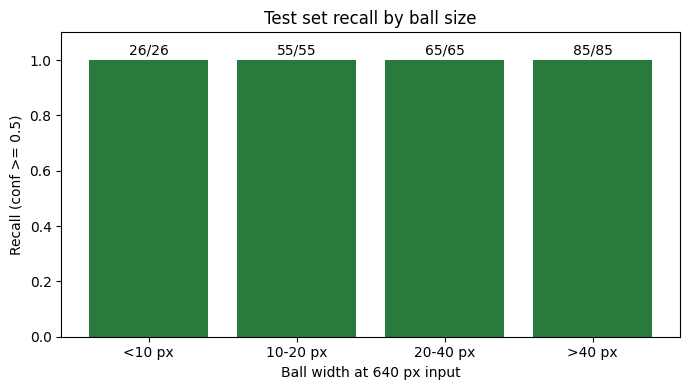

In [10]:
# =====================================================================
# STEP 10: RECALL PER BALL SIZE AT CONF 0.5 (TEST SET)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

BUCKETS = [(0, 10, "<10 px"), (10, 20, "10-20 px"), (20, 40, "20-40 px"), (40, 1e9, ">40 px")]
found, total = np.zeros(len(BUCKETS)), np.zeros(len(BUCKETS))
tp = fp = 0

for img_path in sorted(glob.glob(f"{DATA_ROOT}/images/test/*.jpg")):
    W, H = Image.open(img_path).size
    lbl_path = img_path.replace("/images/", "/labels/").replace(".jpg", ".txt")
    gt = []
    for line in open(lbl_path).read().splitlines():
        if line.strip():
            _, x, y, w, h = map(float, line.split())
            gt.append(((x - w/2) * W, (y - h/2) * H, (x + w/2) * W, (y + h/2) * H))
    result = best.predict(img_path, imgsz=IMGSZ, conf=CONF_DEPLOY, device=0, verbose=False)[0]
    preds = result.boxes.xyxy.cpu().numpy().tolist()      # already sorted by confidence
    matched = set()
    for p in preds:
        scores = [(iou(p, g), j) for j, g in enumerate(gt) if j not in matched]
        if scores and max(scores)[0] >= 0.5:
            matched.add(max(scores)[1]); tp += 1
        else:
            fp += 1
    for j, g in enumerate(gt):
        width_640 = (g[2] - g[0]) * IMGSZ / max(W, H)
        k = next(i for i, (lo, hi, _) in enumerate(BUCKETS) if lo <= width_640 < hi)
        total[k] += 1
        found[k] += j in matched

SIZE_RECALL = [{"size": lab, "balls": int(t), "found": int(f),
                "recall": round(f / t, 4) if t else None}
               for (_, _, lab), f, t in zip(BUCKETS, found, total)]
DEPLOY = {"conf": CONF_DEPLOY, "true_positives": tp, "false_positives": fp,
          "missed": int(total.sum() - found.sum()),
          "precision": round(tp / (tp + fp), 4) if tp + fp else None,
          "recall": round(found.sum() / total.sum(), 4)}

print(f"At conf {CONF_DEPLOY}: precision {DEPLOY['precision']}, recall {DEPLOY['recall']}, "
      f"TP {tp}, FP {fp}, missed {DEPLOY['missed']}")
for r in SIZE_RECALL:
    print(f"  {r['size']:<9} balls {r['balls']:>4}   found {r['found']:>4}   recall {r['recall']}")

os.makedirs(OUT_DIR, exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4))
labels = [r["size"] for r in SIZE_RECALL]
values = [r["recall"] or 0 for r in SIZE_RECALL]
bars = ax.bar(labels, values, color="#2b7a3d")
for b, r in zip(bars, SIZE_RECALL):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02,
            f"{r['found']}/{r['balls']}", ha="center")
ax.set_ylim(0, 1.1)
ax.set_xlabel("Ball width at 640 px input")
ax.set_ylabel(f"Recall (conf >= {CONF_DEPLOY})")
ax.set_title("Test set recall by ball size")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/recall_by_ball_size.png", dpi=200)
plt.show()

---
## STEP 11: Example detections on test images
Draws the model's detections (conf >= 0.5) on 8 random test images, for your report and presentation.

In [11]:
# =====================================================================
# STEP 11: EXAMPLE PREDICTIONS
# =====================================================================
import random
examples = random.Random(SEED).sample(sorted(glob.glob(f"{DATA_ROOT}/images/test/*.jpg")), 8)
best.predict(examples, imgsz=IMGSZ, conf=CONF_DEPLOY, device=0, save=True, line_width=3,
             project=RUN_DIR, name="v2_examples", exist_ok=True, verbose=False)
print("Saved to:", f"{RUN_DIR}/v2_examples")

Results saved to /content/drive/MyDrive/MCTR474/vision/runs/v2_examples
Saved to: /content/drive/MyDrive/MCTR474/vision/runs/v2_examples


---
## STEP 12: Export to NCNN for the Raspberry Pi
Creates `best_ncnn_model`, the same format your Pi already runs at about 9 FPS.

In [12]:
# =====================================================================
# STEP 12: NCNN EXPORT
# =====================================================================
ncnn_path = best.export(format="ncnn", imgsz=IMGSZ)
print("NCNN model:", ncnn_path)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/MCTR474/vision/runs/v2_train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)
requirements: Ultralytics requirement ['ncnn'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 1 package in 139ms
Prepared 1 package in 127ms
Installed 1 package in 1ms
 + ncnn==1.0.20260526

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

requirements: Ultralytics requirement ['pnnx==20260526'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 30 packages in 1

---
## STEP 13: Pack everything into ONE folder and ONE zip on Google Drive
After this cell, everything you need is in **MyDrive > MCTR474 > vision > deliverables_v2.zip**.

In [13]:
# =====================================================================
# STEP 13: COLLECT DELIVERABLES
# =====================================================================
import json

os.makedirs(f"{OUT_DIR}/model", exist_ok=True)
for sub in ("training_plots", "validation_plots", "test_plots", "example_detections"):
    os.makedirs(f"{OUT_DIR}/{sub}", exist_ok=True)

# Model files (renamed v2 so they can never be confused with the old model)
shutil.copy(f"{TRAIN_DIR}/weights/best.pt", f"{OUT_DIR}/model/best_v2.pt")
shutil.copytree(ncnn_path, f"{OUT_DIR}/model/best_v2_ncnn_model", dirs_exist_ok=True)

# Plots and logs
for f in glob.glob(f"{TRAIN_DIR}/*.png") + glob.glob(f"{TRAIN_DIR}/*.jpg"):
    shutil.copy(f, f"{OUT_DIR}/training_plots/")
shutil.copy(f"{TRAIN_DIR}/results.csv", f"{OUT_DIR}/training_results.csv")
shutil.copy(f"{TRAIN_DIR}/args.yaml", f"{OUT_DIR}/training_args.yaml")
for split in ("val", "test"):
    for f in glob.glob(f"{RUN_DIR}/v2_{split}/*.png") + glob.glob(f"{RUN_DIR}/v2_{split}/*.jpg"):
        shutil.copy(f, f"{OUT_DIR}/{'validation' if split == 'val' else 'test'}_plots/")
for f in glob.glob(f"{RUN_DIR}/v2_examples/*.jpg"):
    shutil.copy(f, f"{OUT_DIR}/example_detections/")

# All numbers for the report in one file
report = {
    "model": "YOLOv8n (COCO-pretrained, transfer learning)",
    "ultralytics_version": ULTRALYTICS_VERSION,
    "dataset": {"train": 1005, "val": 73, "test": 70,
                "note": "335 original train images + 670 augmented copies; val/test unaugmented"},
    "settings": {"imgsz": IMGSZ, "epochs_max": EPOCHS, "patience": PATIENCE, "batch": BATCH,
                 "seed": SEED, "class_names": CLASS_NAMES},
    "epochs_run": EPOCHS_RUN, "best_epoch": BEST_EPOCH,
    "metrics": METRICS,
    "test_at_deploy_conf": DEPLOY,
    "test_recall_by_size": SIZE_RECALL,
}
with open(f"{OUT_DIR}/metrics_v2.json", "w") as f:
    json.dump(report, f, indent=2)

# Copy of this dataset config, then zip everything
shutil.copy(DATA_YAML, f"{OUT_DIR}/data_colab.yaml")
shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print(json.dumps(report, indent=2))
print("\nDONE. Download: MyDrive/MCTR474/vision/deliverables_v2.zip")

{
  "model": "YOLOv8n (COCO-pretrained, transfer learning)",
  "ultralytics_version": "8.4.177",
  "dataset": {
    "train": 1005,
    "val": 73,
    "test": 70,
    "note": "335 original train images + 670 augmented copies; val/test unaugmented"
  },
  "settings": {
    "imgsz": 640,
    "epochs_max": 150,
    "patience": 30,
    "batch": 16,
    "seed": 474,
    "class_names": [
      "golf-ball"
    ]
  },
  "epochs_run": 146,
  "best_epoch": 116,
  "metrics": {
    "validation": {
      "precision": 0.9962,
      "recall": 0.9918,
      "mAP50": 0.9948,
      "mAP50_95": 0.9311
    },
    "test": {
      "precision": 0.9903,
      "recall": 1.0,
      "mAP50": 0.995,
      "mAP50_95": 0.9408
    }
  },
  "test_at_deploy_conf": {
    "conf": 0.5,
    "true_positives": 231,
    "false_positives": 1,
    "missed": 0,
    "precision": 0.9957,
    "recall": 1.0
  },
  "test_recall_by_size": [
    {
      "size": "<10 px",
      "balls": 26,
      "found": 26,
      "recall": 1.0
    },
